# DiT：用 Transformer 生成图像

语言模型处理字符，DiT 处理图片小块，并额外接收一个时间。本例用 **Flow Matching** 训练 DiT：从噪声走向真实图片，模型负责预测每一步应该往哪里移动。

先完成四次参数更新，再看一次采样过程；此时还不能生成清晰数字。

In [1]:
from qutai import Stream, generation, nn, visualization
from examples.data.data import load_mnist

device = "cuda"

## 1. 看一张图片

仍然使用 MNIST。数据读取放在 `examples/data/data.py`，Notebook 只负责展示模型与训练。

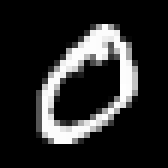

In [8]:
images, labels = load_mnist("train")
visualization.Image.from_tensor(images[1], value_range=(0, 1))

## 2. 搭模型和数据流

`DiT` 把 28×28 图片切成 7×7 的小块。`generation.Model` 把网络和生成方法放在一起。

`Stream` 为每张图片随机准备噪声和时间，输出三项：`inputs` 是当前图片，`times` 是当前时间，`targets` 是从噪声走向原图的速度。

In [12]:
method = generation.FlowMatching(steps=64)
model = generation.Model(
    nn.DiT(1, 28, features=64, heads=4, depth=2, hidden_features=256),
    method=method,
).to(device)

optimizer = nn.AdamW(model, learning_rate=0.001, weight_decay=0)
loss_function = nn.MSE()
data = Stream([images[labels.index(0)]] * 16, method=method, batch_size=16, device=device)

## 3. 训练

循环和其他教程相同，只是 DiT 还需要接收 `times`。预测速度与目标速度越接近，MSE 越小。

In [15]:
epochs = 1024
# 每轮遍历一次数据；每批独立完成一次参数更新。
for epoch in range(epochs):
    for inputs, times, targets in data:
        optimizer.zero_grad()
        loss = loss_function(model(inputs, times), targets)
        loss.backward()
        nn.clip_grad_norm(model, 1.0)
        optimizer.step()
    print(f"epoch {epoch + 1}/{epochs}  loss {loss.item():.4f}")

▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰ 100.0%  1/1  0.1s
epoch 1/1024  loss 0.0487
▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰ 100.0%  1/1  0.0s
epoch 2/1024  loss 0.0635
▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰ 100.0%  1/1  0.0s
epoch 3/1024  loss 0.0176
▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰ 100.0%  1/1  0.0s
epoch 4/1024  loss 0.0338
▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰ 100.0%  1/1  0.0s
epoch 5/1024  loss 0.0436
▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰ 100.0%  1/1  0.0s
epoch 6/1024  loss 0.0320
▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰ 100.0%  1/1  0.1s
epoch 7/1024  loss 0.0500
▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰ 100.0%  1/1  0.0s
epoch 8/1024  loss 0.0312
▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰ 100.0%  1/1  0.1s
epoch 9/1024  loss 0.0209
▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰ 100.0%  1/1  0.0s
epoch 10/1024  loss 0.0231
▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰ 100.0%  1/1  0.0s
epoch 11/1024  loss 0.0162
▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰ 100.0%  1/1  0.1s
epoch 12/1024  loss 0.0174
▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰ 100.0%  1/1  0.0s
epoch 13/1024  loss 0.0797
▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰ 100.0%  1/1  0.0s
epoch 14/1024  loss 0.0605
▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰ 100.

## 4. 从噪声开始采样

`trajectory()` 返回初始噪声和后面每一步的图片。这里每隔两步显示一张；训练更多轮后再观察最终图片是否逐渐接近数字。


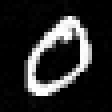
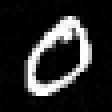
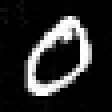
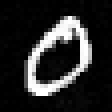
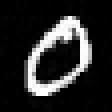
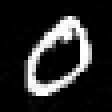
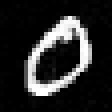
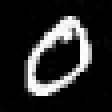

In [16]:
samples = model.sample(count=8)
visualization.ImageCombine([visualization.Image.from_tensor(samples[i], scale=4) for i in range(8)], columns=8)